# 01 — EDA: raw FD001 training data audit

**Goal:** check the raw training file *before* any cleaning, so later steps (RUL labels, engine-ID splits, rolling features) rest on verified assumptions.

Checks: shape, column names, engine counts, cycle order, missing values, duplicate rows.

Data: `train_FD001.txt`, `test_FD001.txt` and `RUL_FD001.txt` in `data/raw/`. Run this notebook from the `notebooks/` folder.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from rul_prediction.data import audit_raw_data, load_cmapss_file

TRAIN_PATH = PROJECT_ROOT / "data" / "raw" / "train_FD001.txt"
train = load_cmapss_file(TRAIN_PATH)

## Shape and column names

26 columns = engine ID, cycle, 3 operating settings, 21 sensors.

In [2]:
print("shape:", train.shape)
print(list(train.columns))
train.head()

shape: (20631, 26)
['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [3]:
train.dtypes.value_counts()

float64    22
int64       4
Name: count, dtype: int64

## Structural audit summary

In [4]:
summary = audit_raw_data(train)
for check, value in summary.items():
    print(f"{check:36s} {value}")

n_rows                               20631
n_columns                            26
n_engines                            100
engine_id_min                        1
engine_id_max                        100
cycles_per_engine_min                128
cycles_per_engine_median             199.0
cycles_per_engine_max                362
missing_values_total                 0
duplicate_rows                       0
duplicate_engine_cycle_pairs         0
cycles_start_at_1_and_consecutive    True
sorted_by_engine_then_cycle          True


## Cycles per engine

Each training engine runs to failure, so its last cycle is its failure point. Trajectory length varies by engine, which is why RUL must be computed per engine.

In [5]:
cycles_per_engine = train.groupby("engine_id")["cycle"].max()
cycles_per_engine.describe()

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

## Missing values per column

In [6]:
missing = train.isna().sum()
missing[missing > 0] if missing.any() else "No missing values in any column"

'No missing values in any column'

## Test file audit

Test engines stop **before** failure, so trajectories are shorter than in training. The same structural checks must still pass, because predictions are made at each test engine's last cycle.

In [7]:
from rul_prediction.data import load_rul_file

test = load_cmapss_file(PROJECT_ROOT / "data" / "raw" / "test_FD001.txt")
test_summary = audit_raw_data(test)
for check, value in test_summary.items():
    print(f"{check:36s} {value}")

n_rows                               13096
n_columns                            26
n_engines                            100
engine_id_min                        1
engine_id_max                        100
cycles_per_engine_min                31
cycles_per_engine_median             133.5
cycles_per_engine_max                303
missing_values_total                 0
duplicate_rows                       0
duplicate_engine_cycle_pairs         0
cycles_start_at_1_and_consecutive    True
sorted_by_engine_then_cycle          True


## Test RUL answer key alignment

`RUL_FD001.txt` has one value per line and no engine column; line *i* is test engine *i*. Its engine IDs must match the test file exactly, otherwise predictions would be compared with the wrong answers.

The RUL **values** are the official test labels: they are used only for final evaluation, so we deliberately do not summarise their distribution here (it must not influence an RUL cap or hyperparameters).

In [8]:
test_rul = load_rul_file(PROJECT_ROOT / "data" / "raw" / "RUL_FD001.txt")
test_engine_ids = sorted(test["engine_id"].unique())

# Fail loudly: a mismatch means predictions would be scored against the wrong engines.
assert test_rul["engine_id"].tolist() == test_engine_ids, "RUL file does not match test engine IDs"
print("RUL rows:", len(test_rul), "| test engines:", len(test_engine_ids), "| engine IDs match")

RUL rows: 100 | test engines: 100 | engine IDs match


## Sensors across the engine's life (training engines only)

Each thin line is one engine; the x-axis is **cycles before failure** (RUL), so all engines line up at failure (RUL 0) on the right. The black line is the median over the training engines that reach each RUL. Engines have different lifetimes, so fewer engines contribute at large RUL; the plot stops at RUL 125, where at least the number of engines printed below still contribute. Validation engines are left out so that EDA cannot influence choices that are later scored on them.

engines contributing to the median: 80 to 80 of 80


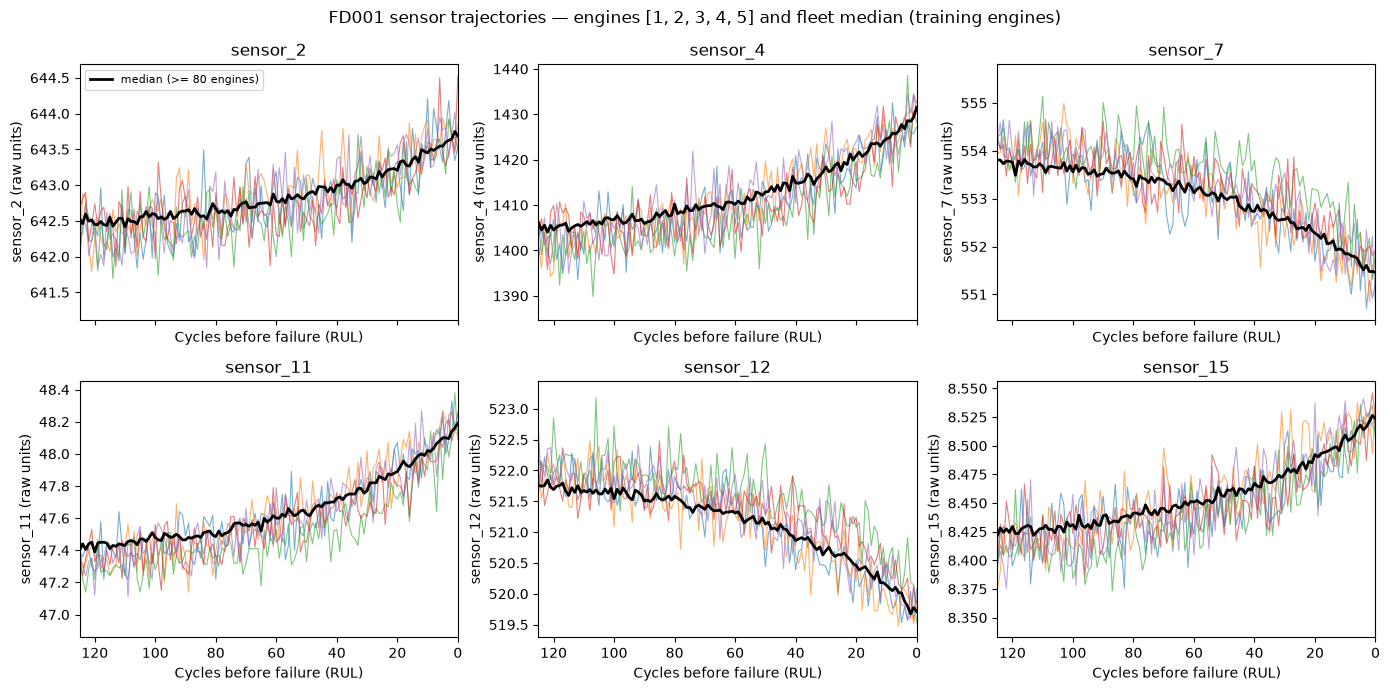

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

from rul_prediction.data import SENSOR_COLUMNS, SETTING_COLUMNS
from rul_prediction.features import NEAR_CONSTANT_SHARE, select_informative_sensors
from rul_prediction.splits import split_by_engine, split_engine_ids
from rul_prediction.targets import add_train_rul

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

labelled = add_train_rul(train)
train_ids, val_ids = split_engine_ids(labelled["engine_id"])
train_df, _ = split_by_engine(labelled, val_ids)

PLOT_SENSORS = ["sensor_2", "sensor_4", "sensor_7", "sensor_11", "sensor_12", "sensor_15"]
EXAMPLE_ENGINES = train_ids[:5]
# Engines live 128-362 cycles, so at RUL 200 only about half contribute to the
# median. Stop where nearly all training engines still have history.
MAX_RUL_SHOWN = 125

engines_per_rul = train_df[train_df["rul"] <= MAX_RUL_SHOWN].groupby("rul")["engine_id"].nunique()
min_engines = int(engines_per_rul.min())
print(f"engines contributing to the median: {min_engines} to {int(engines_per_rul.max())} of {len(train_ids)}")

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, sensor in zip(axes.flat, PLOT_SENSORS):
    for engine_id in EXAMPLE_ENGINES:
        engine = train_df[train_df["engine_id"] == engine_id]
        ax.plot(engine["rul"], engine[sensor], linewidth=0.8, alpha=0.6)
    fleet_median = train_df[train_df["rul"] <= MAX_RUL_SHOWN].groupby("rul")[sensor].median()
    ax.plot(fleet_median.index, fleet_median, color="black", linewidth=2, label=f"median (>= {min_engines} engines)")
    ax.set_xlim(MAX_RUL_SHOWN, 0)
    ax.set_title(sensor)
    ax.set_xlabel("Cycles before failure (RUL)")
    ax.set_ylabel(f"{sensor} (raw units)")
axes.flat[0].legend(fontsize=8)
fig.suptitle(f"FD001 sensor trajectories — engines {EXAMPLE_ENGINES} and fleet median (training engines)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_sensor_trajectories.png", dpi=150)
plt.show()

## Constant and near-constant sensors

Rule (decided on the 80 training engines only): drop a sensor if its most common value covers at least `NEAR_CONSTANT_SHARE` of rows. A sensor that (almost) never changes cannot tell a healthy engine from a failing one, and after scaling it would be all zeros or a few spikes. `corr_with_rul` is shown as supporting evidence, not as the selection rule.

In [10]:
informative = select_informative_sensors(train_df)

sensor_table = pd.DataFrame({
    "unique_values": train_df[SENSOR_COLUMNS].nunique(),
    "most_common_share": [train_df[s].value_counts(normalize=True).iloc[0] for s in SENSOR_COLUMNS],
    "std": train_df[SENSOR_COLUMNS].std(),
    "corr_with_rul": [train_df[s].corr(train_df["rul"]) if train_df[s].nunique() > 1 else float("nan") for s in SENSOR_COLUMNS],
}, index=SENSOR_COLUMNS)
sensor_table["decision"] = ["keep" if s in informative else "remove" for s in SENSOR_COLUMNS]

print(f"rule: remove if most common value covers >= {NEAR_CONSTANT_SHARE:.0%} of training rows")
print(f"kept {len(informative)} sensors:", informative)
sensor_table.round(4)

rule: remove if most common value covers >= 95% of training rows
kept 14 sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


,unique_values,most_common_share,std,corr_with_rul,decision
sensor_1,1,1.0000,0.0000,NaN,remove
sensor_2,306,0.0093,0.5028,-0.6147,keep
sensor_3,2908,0.0016,6.1629,-0.5955,keep
sensor_4,3897,0.0010,9.0455,-0.6867,keep
sensor_5,1,1.0000,0.0000,NaN,remove
sensor_6,2,0.9799,0.0014,-0.1303,remove
sensor_7,498,0.0059,0.8884,0.6673,keep
sensor_8,50,0.0588,0.0701,-0.5698,keep
sensor_9,5821,0.0009,21.3677,-0.4188,keep
sensor_10,1,1.0000,0.0000,NaN,remove


### Operating settings

NASA's readme lists FD001 as **one operating condition (sea level)**. `setting_3` is constant; `setting_1` and `setting_2` only jitter around zero.

In [11]:
pd.DataFrame({
    "unique_values": train_df[SETTING_COLUMNS].nunique(),
    "std": train_df[SETTING_COLUMNS].std(),
    "corr_with_rul": [train_df[s].corr(train_df["rul"]) if train_df[s].nunique() > 1 else float("nan") for s in SETTING_COLUMNS],
}, index=SETTING_COLUMNS).round(4)

,unique_values,std,corr_with_rul
setting_1,157,0.0022,-0.0022
setting_2,13,0.0003,0.0025
setting_3,1,0.0000,NaN


## Findings

_All values below come from the outputs of the cells above._

- **Rows / columns:** 20,631 rows × 26 columns (engine ID, cycle, 3 settings, 21 sensors). `engine_id` and `cycle` are integers; the other 24 columns are floats.
- **Engines:** 100 engines, IDs 1–100.
- **Trajectory length (cycles per engine):** min 128, median 199, mean 206.3, max 362. Engines fail at very different cycles, so RUL must be computed per engine.
- **Missing values:** none in any column.
- **Duplicates:** 0 duplicate rows and 0 duplicate (engine, cycle) pairs.
- **Cycle order:** every engine's cycles start at 1 and run consecutively with no gaps; rows are already sorted by engine, then cycle.

**Test file and answer key:**

- **Test file:** 13,096 rows × 26 columns, 100 engines (IDs 1–100); 31 to 303 cycles per engine (median 133.5). No missing values or duplicates; cycles start at 1, are consecutive and sorted. Test trajectories are shorter than training ones because they stop before failure.
- **`RUL_FD001.txt`:** 100 values, one per test engine; engine IDs match the test file exactly. Values are kept for final evaluation only and are not summarised here.


**Sensor behaviour during degradation (training engines, RUL 125 to 0):**

- `sensor_2`, `sensor_4`, `sensor_11` and `sensor_15` **rise** and `sensor_7` and `sensor_12` **fall** as RUL approaches 0. Visually, the change is gradual at first and steepest over roughly the last 50 cycles (read from the plot, not computed).
- Single readings are noisy (thin lines overlap heavily), while the fleet median shows a clear trend. This motivates **rolling mean** (smooth the noise) and **rolling slope** (how fast a sensor is drifting) features.

**Constant / near-constant sensors (feature selection, decided on training engines only):**

- Removed (most common value covers >= 95% of rows): `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18`, `sensor_19` (one value only) and `sensor_6` (two values, 98.0% one value, |corr with RUL| 0.13).
- Kept 14 sensors: `sensor_2, 3, 4, 7, 8, 9, 11, 12, 13, 14, 15, 17, 20, 21`; each has |corr with RUL| between 0.33 and 0.70. The highest most-common-value share among kept sensors is 26% (`sensor_17`), so the 95% threshold is not a borderline choice.
- Operating settings: `setting_3` is constant and `setting_1`/`setting_2` have |corr with RUL| < 0.01. Together with NASA's readme (FD001 has a single operating condition; external source, not checked by code here), this is a design choice to leave the settings out of engineered features. Near-zero linear correlation does not rule out non-linear information.


**Implication:** all structural checks pass, so no structural cleaning is needed. RUL labels and engine-ID splits can be built directly on this table. The raw table itself is never modified; sensor removal happens in the feature step (`features.select_informative_sensors`).